#Tarefa Avaliativa 4

*   Disciplina: Física com Python 1 (2026.2) — CBPF
*   Autor: Guilherme Rodrigues Bento
*   Obs: Código desenvolvido para fins de avaliação acadêmica. Disponibilizado publicamente sob a Licença MIT para consulta educacional.

##Parte 1

 Vá na tabela do slide 36 dessa [apresentação](https://https://docs.google.com/presentation/d/1Cbj5JP3zd2teq8xfyt7Li24cBLYrC5tI2MuddnAfN9w/edit?usp=sharing) e **escolha 2 mapas caóticos** onde você terá que fazer uma simulação para comparar com os resultados analíticos do expoente de Lyapunov e densidade invariante

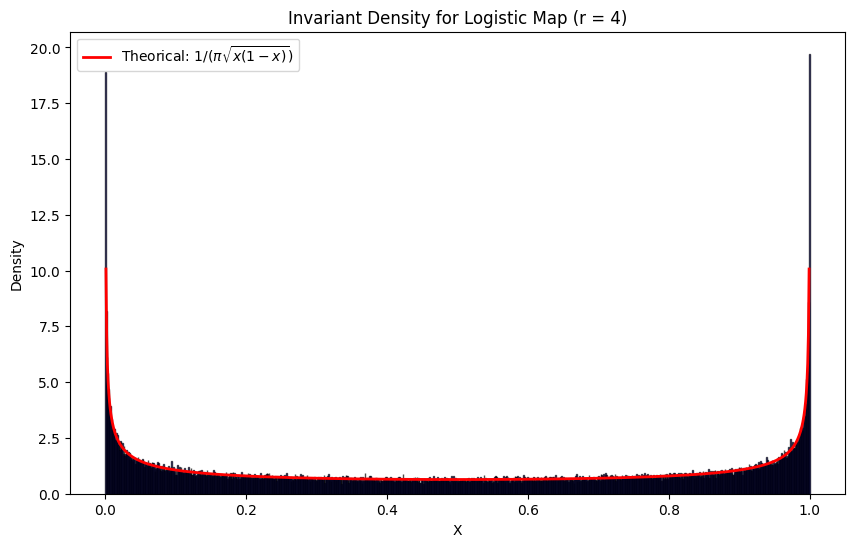

In [ ]:
# -------------------- 0. Importing Packages --------------------

import numpy as np
import matplotlib.pyplot as plt

# -------------------- 1. Generating the Invariant Density --------------------

# Defining some parameters
x = 1/np.pi    # Initial condition
N_ite = 10**5  # Number of iterations
X = []         # Orbit generated by the logistic map (r = 4)

# Simulating orbit
for _ in range(N_ite):
    x = 4 * x * (1 - x)
    X.append(x)

# Theoretical result
x_teo = np.linspace(0.001, 0.999, 1000)
y_teo = 1 / (np.pi * np.sqrt(x_teo * (1 - x_teo)))

# -------------------- 2. Plotting the Graph --------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(X, bins=1000, density=True, alpha=0.7, color='blue', edgecolor='black')
ax.plot(x_teo, y_teo, color='red', lw=2, label=r'Theoretical: $1 / (\pi\sqrt{x(1-x)})$')
ax.set_title("Invariant Density for Logistic Map (r = 4)")
ax.set_xlabel("X")
ax.set_ylabel("Density")
ax.legend()

plt.show()

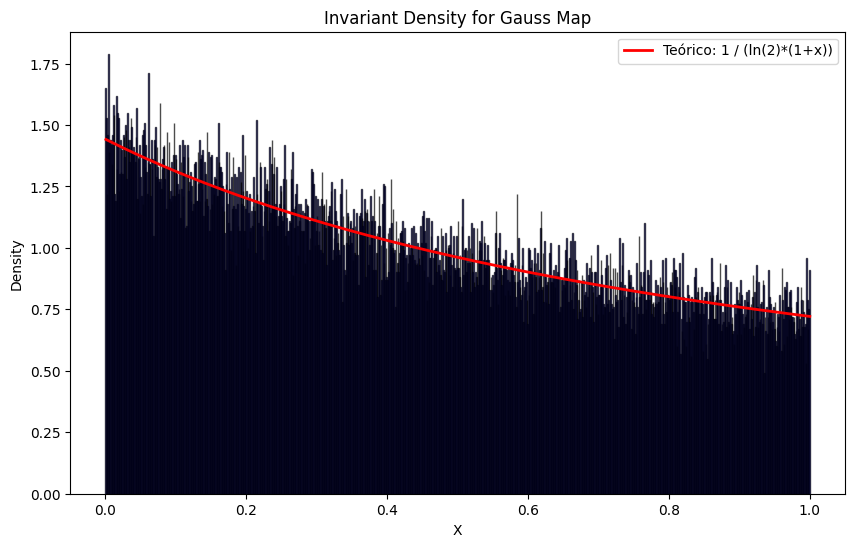

In [ ]:
# -------------------- 0. Importing Packages --------------------

import numpy as np
import matplotlib.pyplot as plt

# -------------------- 1. Generatint the Invariant Density --------------------

# Defining some parameters
x = 1/np.pi    # Initial condition
N_ite = 10**5  # Number of iterations
X = []         # Orbit generated by the gauss map

# Simulating orbit
for _ in range(N_ite):
  x = (1/x) % 1
  X.append(x)

# Theoretical resul
x_teo = np.linspace(0.001, 1, 1000)
y_teo = 1 / (np.log(2) * (1 + x_teo))

# -------------------- 2. Plotting the Graphs --------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(X, bins = 1000, density=True, alpha=0.7, color='blue', edgecolor='black')
ax.plot(x_teo, y_teo, color='red', lw=2, label='Theoretical: 1 / (ln(2)*(1+x))')
ax.set_title(f"Invariant Density for Gauss Map")
ax.set_xlabel("X")
ax.set_ylabel("Density")
ax.legend()

plt.show()

##Parte 2




>>>> Logistic map

Sobre o artigo abaixo: use a Eq.5 para obter computacionalmente os resultados equivalentes aos experimentais mostrados na Fig.(5,7)

* Suneel, Madhekar. "Electronic circuit realization of the logistic map." Sadhana (2006). [LINK](https://www.ias.ac.in/public/Volumes/sadh/031/01/0069-0078.pdf)



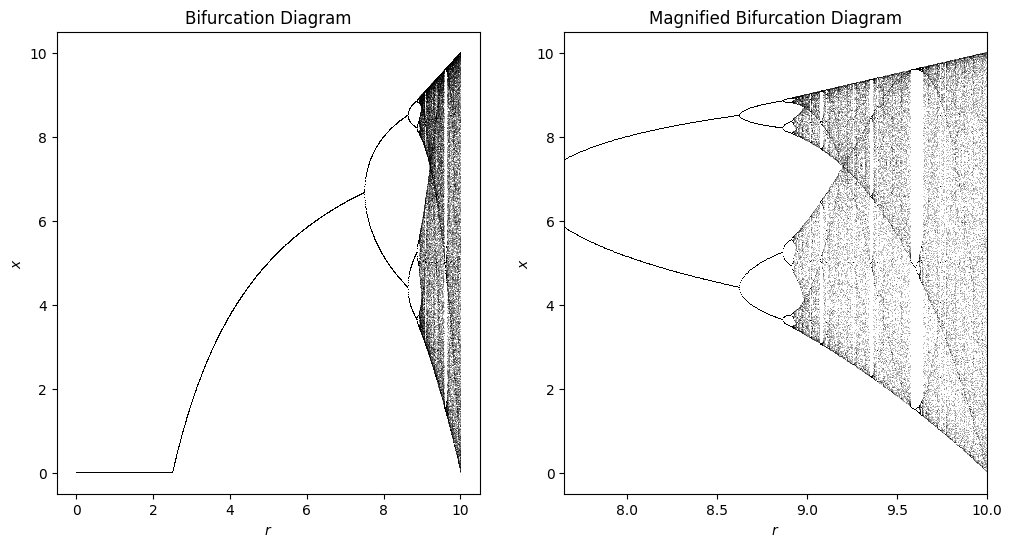

In [ ]:
# -------------------- 0. Importing Packages --------------------

import numpy as np
import matplotlib.pyplot as plt

# -------------------- 1. Generating Bifurcation Diagram --------------------

# Defining the function for the bifurcation diagram of the modified logistic map
def bifurcation(r_min, r_max, N, N_ite, N_burn):
    r = np.linspace(r_min, r_max, N)
    x = (1/np.pi) * np.ones(N)

    # Discarding the transient
    for _ in range(N_burn):
        x = (r * x * (10 - x))/25

    r_plot, x_plot = [], []

    # Generating the final orbit
    for _ in range(N_ite):
        x = r * x * (10 - x)/25
        r_plot.append(r.copy())
        x_plot.append(x.copy())

    return np.array(r_plot).flatten(), np.array(x_plot).flatten()

r_main, x_main = bifurcation(0.00, 10.00, 2000, 200, 1000)

# -------------------- 2. Plotting the Graphs --------------------

fig, ax = plt.subplots(1, 2, figsize=(12,6))

# Plotting the bifurcation diagram
ax[0].plot(r_main, x_main, ',k', alpha=0.25)
ax[0].set_xlabel(r'$r$')
ax[0].set_ylabel(r'$x$')
ax[0].set_title('Bifurcation Diagram')

# Plotting the magnified bifurcation diagram
ax[1].plot(r_main, x_main, ',k', alpha=0.25)
ax[1].set_xlabel(r'$r$')
ax[1].set_ylabel(r'$x$')
ax[1].set_xlim(7.65, 10.00)
ax[1].set_title('Magnified Bifurcation Diagram')


plt.show()

>>>> Cossenoidal map

Sobre o artigo abaixo: use a Eq.5 para reproduzir a Fig.4. Compare com o correspondente resultado experimental na Fig.3.

* Artigo: Ma, Yu-Han, et al. "Experimental system of coupled map lattices." Frontiers of Physics (2015) [LINK](https://www.researchgate.net/profile/Yu-Han-Ma/publication/277567812_Experimental_system_of_coupled_map_lattices/links/59e40e4aaca2724cbfe3bb01/Experimental-system-of-coupled-map-lattices.pdf)



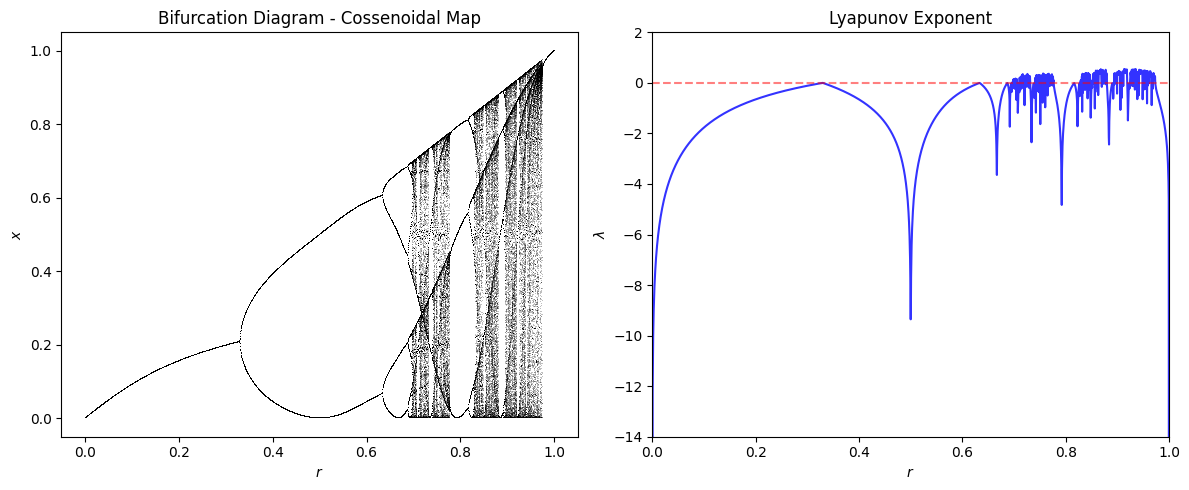

In [ ]:
# -------------------- 0. Importing Packages --------------------

import numpy as np
import matplotlib.pyplot as plt

# -------------------- 1. Generating Bifurcation Diagram --------------------

# Defining the function for the bifurcation diagram
def bifurcation(r_min, r_max, N, N_ite, N_burn):
    r = np.linspace(r_min, r_max, N)
    x = (1/np.pi) * np.ones(N)

    # Discarding the transient
    for _ in range(N_burn):
        x = (r/2) * (1 + np.cos(2*np.pi*x))

    r_plot, x_plot = [], []
    L = np.zeros(N)

    # Generating the final orbit
    for _ in range(N_ite):
        x = (r/2) * (1 + np.cos(2*np.pi*x))

        # Calculating the Lyapunov exponent
        df = -r * np.pi * np.sin(2 * np.pi * x)
        L += np.log(np.abs(df) + 1e-12) # Avoiding a division by zero

        r_plot.append(r.copy())
        x_plot.append(x.copy())

    L = L / N_ite

    return np.array(r_plot).flatten(), np.array(x_plot).flatten(), r, L

r_main, x_main, r_lyap, L_main = bifurcation(0.0, 1.0, 2000, 200, 1000)

# -------------------- 2. Plotting the Graphs --------------------

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Plotting the bifurcation diagram
ax[0].plot(r_main, x_main, ',k', alpha=0.25)
ax[0].set_xlabel(r'$r$')
ax[0].set_ylabel(r'$x$')
ax[0].set_title('Bifurcation Diagram - Cossenoidal Map')

# Plotting the Lyapunov Exponent
ax[1].plot(r_lyap, L_main, 'b-', alpha=0.8)
ax[1].axhline(0, color='red', linestyle='--', alpha=0.5)
ax[1].set_xlabel(r'$r$')
ax[1].set_ylabel(r'$\lambda$')
ax[1].set_xlim(0.0, 1.0)
ax[1].set_ylim(-14.0, 2.0)
ax[1].set_title('Lyapunov Exponent')

plt.tight_layout()
plt.show()